In [ ]:
1. 인스타그램 API 활용 데이터 수집 대상 2가지
- 인스타그램 내 Owned Media 채널 컨텐츠 수집 (기업, 브랜드 -> 자체 공식 채널)  (Graph API) 
- 인스타그램 내 일반사용자들이 업로드한 컨텐츠 수집(Hashtag Search)

2. 인스타그램 어플리케이션 = 앱 (스마트폰) 
- 앱 > 설정 > 계정 변경/변환 탭
- 일반 > 크리에이터 | 프로페셔널 (인스타그램 광고 집행, 비지니스 목적) -> 필수

3. 페이스북 사이트 > 페이지 개설 > 페이지 & 2번 프로페셔널 계정 연동
- 페이스북 페이지 개설 후 우측 상단 프로필 영역 전환(일반사용자 -> 페이지관리자 모드)
- 좌측 사이드 메뉴 > 연동하기 접속 (인스타그램 프로페셔널 계정 찾아오는 버튼 -> 연결) 

4. 페이스북 비지니스 관리자 = 광고캠페인
- 위 2~3 과정을 통해서 만들어진 환경설정을 기반으로 비지니스 포트폴리오 생성
- 해당 비지니스 포트폴리오 내 페이지 활성화
- 활성화 : 인스타그램 프로페셔널 + 페이스북 페이지 개설 및 연동

5. 페이스북 개발자센터 접속 
- 페이스북 광고캠페인 관리자 (비즈니스 광고 캠페인 세팅) : business.facebook.com
- 페이스북 개발자센터 : developers.facebook.com
- 우측 상단 앱 생성하기 
- 앱 이름 작명 : 인스타그램 연상 키워드 안됨 -> sns_contents_api_261030
- "인스타그램에서 메세지 및 컨텐츠 관리" 체크
- 4번까지 완료가 되어있어야지만, 결국 비지니스 포트폴리오 선택 가능 > 다음 단계 이동

6. 인스타그램에서 메시지 및 컨텐츠 관리 맞춤 설정 이용 사례 클릭
- 앱 = 인스타스램의 어떤 범위까지 사용할 것인지 설정
- 페이스북 로그인이 포함된 API 설정 메뉴 클릭
- 1. 필수 권한 추가 > 모든 권한 승인요청

7. 정상적으로 허가되었는지 확인 필요 & 해시태그 기반으로 값 검색 -> Token 발급
- developers.facebook.com/tools/explorer -> 그래프 API 탐색기
- 토큰 발급 전, 권한 추가부터 시작
- instagram basic
- pages_show_list 
- pages_read_engagement

8. 토큰 정상 발급 
- 

9. Graph API 방식 컨텐츠 수집
- me/permisions
- me?fields=id.name
- 비지니스 포트폴리오 페이지 : 비지니스 목적으로 생성해놓은 페이지 (2번~3번단계) 고유 ID
- 우리가 우리 자체 채널 컨텐츠 : 너 정말로 자체 채널 소유주? 관리자이니?
- 일반 사용자 컨텐츠를 수집할 때도 너가 정말 비지니스 목적으로 채널 관리하고 있는 사람 맞니?
- 비지니스 포트폴리오 페이지 고유 ID : 
-  .
-
- 메타 비지니스 포트폴리오 페이지 고유 id를 통해서 조회한 내가 관리중인 인스타그램 비지니스 id : 
- 
- 

10. Hashtag Search 방식 컨텐츠 수집
- 사이드 메뉴 (이용 사례) > 권한 및 기능
- 인스타그램 퍼블릭 컨텐츠 액세스 추가 

11. 그래프 API 탐색기 이동
- 내가 지금부터 찾고 싶은 키워드 = 해시태그 고유한 ID 조회 
- 치이카와 해시태그 최근 24시간 이내 컨텐츠 조회 
- 인스타그램에서 해시태그를 검색할 때 ig_hashtag_search?user_id=   &q=치이카와 
- 치이카와id : 

12. 치이카와 관련 세부 컨텐츠 조회 
- 치이카와id/recent_media?user_id=페이지 고유 ID&fields=id,caption,media_type,permalink,timestamps&limit=30


In [2]:
import requests
import pandas as pd 

# API 기본 정보
ACCESS_TOKEN = ""
IG_USER_ID = ""
HASHTAG_ID = ""

# 위 API 기본 정보를 활용 GET 방식 데이터를 요청할 URL
# Fast API (파이썬 내 라이브러리 모듈) -> Rest API 방식 
URL = f"https://graph.facebook.com/v26.0/{HASHTAG_ID}/recent_media"


params = {
    "user_id": IG_USER_ID,
    "fields": "id,caption,media_type,permalink,timestamp",
    "limit": 50,
    "access_token": ACCESS_TOKEN 
}  

all_posts = list() #[] 어느것이든 상관 없음

while True : 
    response = requests.get(URL, params=params, timeout=200)
    response.raise_for_status()

    result = response.json()

    posts = result.get("data", [])

    all_posts.extend(posts)

    print(f"현재까지 수집 : {len(all_posts)}건")

    URL = result.get("paging", {}).get("next")

    if not URL : 
        break

    params = None

df = pd.DataFrame(all_posts)

df.to_csv("instagram_치이카와.csv", index=False, encoding="utf-8-sig")
print(f"데이터 수집 완료: {len(df)}건")

    

_IncompleteInputError: incomplete input (2668748099.py, line 32)

In [ ]:
import requests
import pandas as pd 

# API 기본 정보
ACCESS_TOKEN = ""
IG_USER_ID = ""
HASHTAG_ID = ""

# 수집 조건
PAGE_LIMIT = 30
MAX_REQUESTS = 3




# 위 API 기본 정보를 활용 GET 방식 데이터를 요청할 URL
# Fast API (파이썬 내 라이브러리 모듈) -> Rest API 방식 
URL = f"https://graph.facebook.com/v26.0/{HASHTAG_ID}/recent_media"


params = {
    "user_id": IG_USER_ID,
    "fields": "id,caption,media_type,permalink,timestamp",
    "limit": PAGE_LIMIT,
    "access_token": ACCESS_TOKEN 
}  

all_posts = list() #[] 어느것이든 상관 없음

for i in range(MAX_REQUESTS) : 
    response = requests.get(URL, params=params, timeout=200)
    response.raise_for_status()

    result = response.json()

    posts = result.get("data", [])

    all_posts.extend(posts)

    print(f"{i + 1}회 요청 : {len(posts)}건 수집")

    print(f"현재까지 수집 : {len(all_posts)}건")

    URL = result.get("paging", {}).get("next")

    if not URL : 
        break

    params = None

df = pd.DataFrame(all_posts)

df.to_csv("instagram_치이카와.csv", index=False, encoding="utf-8-sig")
print(f"데이터 수집 완료: {len(df)}건")

    

In [3]:
import pandas as pd 

df = pd.read_csv("instagram_치이카와.csv")

df.head()

,id,caption,media_type,permalink,timestamp
0,18098231099388616,치이카와 박스 입고 완료!\n구매 문의는 DM주세용\n\n#치이카와 #우사기 #치이...,VIDEO,https://www.instagram.com/reel/DfGkV_go58T/,2026-10-30T03:02:21+0000
1,18093270125197476,우사기야 잡아먹히지않게 조심해😱😱😱\n\n#페키니즈 #우사기 #먼작귀 #우나 #치이카와,VIDEO,https://www.instagram.com/reel/DfGkSbiOKyj/,2026-10-30T03:01:31+0000
2,17968503579190791,🫠치이카와 먼작귀 태엽자동차 피규어\n치이카와에 진심인 사람… 일단 나 🚗💘\n이 ...,IMAGE,https://www.instagram.com/p/DfGkIqgSoMU/,2026-10-30T02:59:16+0000
3,18015934313979690,금일 모두 업데이트 예정입니다💕\n자사몰에 업데이트되며 가격은 추후 자사몰에서 확인...,IMAGE,https://www.instagram.com/p/DfGjrSHq3Fs/,2026-10-30T02:58:59+0000
4,18012596162988014,🩵 치이카와 입고 안내 🩵\n모두 매장 방문 구매만 가능 (｡˃ ᵕ ˂ )b\n(치...,CAROUSEL_ALBUM,https://www.instagram.com/p/DfGkF_rmqfH/,2026-10-30T02:58:45+0000


In [ ]:
# caption : \s, \t, \n = escape sequence = 문자열이 의미가 있다. = n = new line = 새롭게 행을 추가 = 개행 = 줄바꿈 cleansing 작업하기
# timestamp : 전세계 약속 표준 협정 시간 = 그리니치 천문대 = 국제표준시 != 대한민국 표준시 (+9) 
# ^(시작해야한다), $(~끝난다), [], +

In [5]:
df["caption"] = df["caption"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()

In [6]:
df.head()

,id,caption,media_type,permalink,timestamp
0,18098231099388616,치이카와 박스 입고 완료! 구매 문의는 DM주세용 #치이카와 #우사기 #치이카와굿즈,VIDEO,https://www.instagram.com/reel/DfGkV_go58T/,2026-10-30T03:02:21+0000
1,18093270125197476,우사기야 잡아먹히지않게 조심해😱😱😱 #페키니즈 #우사기 #먼작귀 #우나 #치이카와,VIDEO,https://www.instagram.com/reel/DfGkSbiOKyj/,2026-10-30T03:01:31+0000
2,17968503579190791,🫠치이카와 먼작귀 태엽자동차 피규어 치이카와에 진심인 사람… 일단 나 🚗💘 이 귀여...,IMAGE,https://www.instagram.com/p/DfGkIqgSoMU/,2026-10-30T02:59:16+0000
3,18015934313979690,금일 모두 업데이트 예정입니다💕 자사몰에 업데이트되며 가격은 추후 자사몰에서 확인부...,IMAGE,https://www.instagram.com/p/DfGjrSHq3Fs/,2026-10-30T02:58:59+0000
4,18012596162988014,🩵 치이카와 입고 안내 🩵 모두 매장 방문 구매만 가능 (｡˃ ᵕ ˂ )b (치이카...,CAROUSEL_ALBUM,https://www.instagram.com/p/DfGkF_rmqfH/,2026-10-30T02:58:45+0000


In [7]:
df.info() # 데이터 명세서

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          90 non-null     int64
 1   caption     90 non-null     str  
 2   media_type  90 non-null     str  
 3   permalink   90 non-null     str  
 4   timestamp   90 non-null     str  
dtypes: int64(1), str(4)
memory usage: 46.2 KB


In [9]:
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

df.head()

,id,caption,media_type,permalink,timestamp
0,18098231099388616,치이카와 박스 입고 완료! 구매 문의는 DM주세용 #치이카와 #우사기 #치이카와굿즈,VIDEO,https://www.instagram.com/reel/DfGkV_go58T/,2026-10-30 03:02:21+00:00
1,18093270125197476,우사기야 잡아먹히지않게 조심해😱😱😱 #페키니즈 #우사기 #먼작귀 #우나 #치이카와,VIDEO,https://www.instagram.com/reel/DfGkSbiOKyj/,2026-10-30 03:01:31+00:00
2,17968503579190791,🫠치이카와 먼작귀 태엽자동차 피규어 치이카와에 진심인 사람… 일단 나 🚗💘 이 귀여...,IMAGE,https://www.instagram.com/p/DfGkIqgSoMU/,2026-10-30 02:59:16+00:00
3,18015934313979690,금일 모두 업데이트 예정입니다💕 자사몰에 업데이트되며 가격은 추후 자사몰에서 확인부...,IMAGE,https://www.instagram.com/p/DfGjrSHq3Fs/,2026-10-30 02:58:59+00:00
4,18012596162988014,🩵 치이카와 입고 안내 🩵 모두 매장 방문 구매만 가능 (｡˃ ᵕ ˂ )b (치이카...,CAROUSEL_ALBUM,https://www.instagram.com/p/DfGkF_rmqfH/,2026-10-30 02:58:45+00:00


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype              
---  ------      --------------  -----              
 0   id          90 non-null     int64              
 1   caption     90 non-null     str                
 2   media_type  90 non-null     str                
 3   permalink   90 non-null     str                
 4   timestamp   90 non-null     datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), int64(1), str(3)
memory usage: 44.1 KB


In [11]:
df["timestamp_kst"] = df["timestamp"].dt.tz_convert("Asia/Seoul")
df.head()

,id,caption,media_type,permalink,timestamp,timestamp_kst
0,18098231099388616,치이카와 박스 입고 완료! 구매 문의는 DM주세용 #치이카와 #우사기 #치이카와굿즈,VIDEO,https://www.instagram.com/reel/DfGkV_go58T/,2026-10-30 03:02:21+00:00,2026-10-30 12:02:21+09:00
1,18093270125197476,우사기야 잡아먹히지않게 조심해😱😱😱 #페키니즈 #우사기 #먼작귀 #우나 #치이카와,VIDEO,https://www.instagram.com/reel/DfGkSbiOKyj/,2026-10-30 03:01:31+00:00,2026-10-30 12:01:31+09:00
2,17968503579190791,🫠치이카와 먼작귀 태엽자동차 피규어 치이카와에 진심인 사람… 일단 나 🚗💘 이 귀여...,IMAGE,https://www.instagram.com/p/DfGkIqgSoMU/,2026-10-30 02:59:16+00:00,2026-10-30 11:59:16+09:00
3,18015934313979690,금일 모두 업데이트 예정입니다💕 자사몰에 업데이트되며 가격은 추후 자사몰에서 확인부...,IMAGE,https://www.instagram.com/p/DfGjrSHq3Fs/,2026-10-30 02:58:59+00:00,2026-10-30 11:58:59+09:00
4,18012596162988014,🩵 치이카와 입고 안내 🩵 모두 매장 방문 구매만 가능 (｡˃ ᵕ ˂ )b (치이카...,CAROUSEL_ALBUM,https://www.instagram.com/p/DfGkF_rmqfH/,2026-10-30 02:58:45+00:00,2026-10-30 11:58:45+09:00


In [15]:
analysis_df = df.copy()
analysis_df.head()

,id,caption,media_type,permalink,timestamp,timestamp_kst
0,18098231099388616,치이카와 박스 입고 완료! 구매 문의는 DM주세용 #치이카와 #우사기 #치이카와굿즈,VIDEO,https://www.instagram.com/reel/DfGkV_go58T/,2026-10-30 03:02:21+00:00,2026-10-30 12:02:21+09:00
1,18093270125197476,우사기야 잡아먹히지않게 조심해😱😱😱 #페키니즈 #우사기 #먼작귀 #우나 #치이카와,VIDEO,https://www.instagram.com/reel/DfGkSbiOKyj/,2026-10-30 03:01:31+00:00,2026-10-30 12:01:31+09:00
2,17968503579190791,🫠치이카와 먼작귀 태엽자동차 피규어 치이카와에 진심인 사람… 일단 나 🚗💘 이 귀여...,IMAGE,https://www.instagram.com/p/DfGkIqgSoMU/,2026-10-30 02:59:16+00:00,2026-10-30 11:59:16+09:00
3,18015934313979690,금일 모두 업데이트 예정입니다💕 자사몰에 업데이트되며 가격은 추후 자사몰에서 확인부...,IMAGE,https://www.instagram.com/p/DfGjrSHq3Fs/,2026-10-30 02:58:59+00:00,2026-10-30 11:58:59+09:00
4,18012596162988014,🩵 치이카와 입고 안내 🩵 모두 매장 방문 구매만 가능 (｡˃ ᵕ ˂ )b (치이카...,CAROUSEL_ALBUM,https://www.instagram.com/p/DfGkF_rmqfH/,2026-10-30 02:58:45+00:00,2026-10-30 11:58:45+09:00


In [17]:
analysis_df["media_type"]

0              VIDEO
1              VIDEO
2              IMAGE
3              IMAGE
4     CAROUSEL_ALBUM
           ...      
85             VIDEO
86             VIDEO
87    CAROUSEL_ALBUM
88             IMAGE
89             IMAGE
Name: media_type, Length: 90, dtype: str

In [18]:
analysis_df["media_type"].value_counts()

media_type
VIDEO             41
CAROUSEL_ALBUM    29
IMAGE             20
Name: count, dtype: int64

In [19]:
media_counts = analysis_df["media_type"].value_counts().reset_index()

media_counts.head()

,media_type,count
0,VIDEO,41
1,CAROUSEL_ALBUM,29
2,IMAGE,20


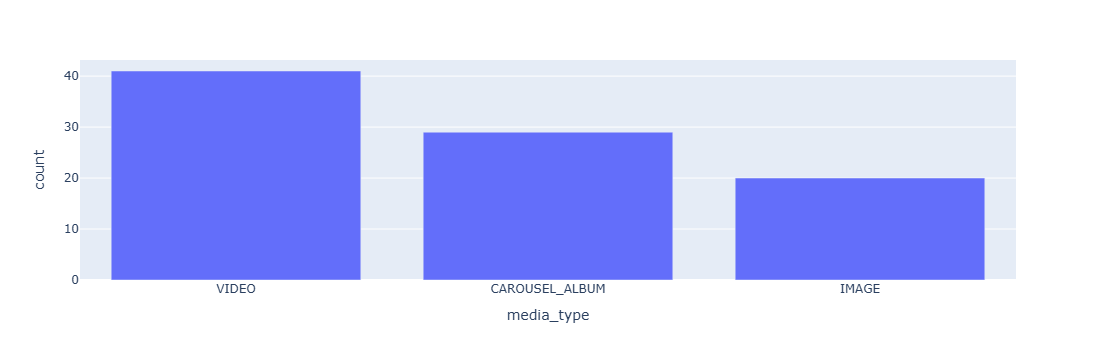

In [20]:
import plotly.express as px

fig = px.bar(
    media_counts,
    x="media_type",
    y="count"
)

fig.show()

In [32]:
# df["caption"].str.findall(r"#[가-힣a-zA-Z0-9]+") # 한국어, 영어(대소문자), 숫자
hashtags = df["caption"].str.findall(r"#[^\W#]+") # 한, 일, 영, 숫 -> [^\W#]

In [33]:
hashtags

0                         [#치이카와, #우사기, #치이카와굿즈]
1                [#페키니즈, #우사기, #먼작귀, #우나, #치이카와]
2     [#모모스테이션익선동, #익선동핫플, #치이카와, #치이카와토벌, #먼작귀]
3                                  [#치이카와, #소품샵]
4                                             []
                         ...                    
85                 [#꽁떼드코코링, #인어섬, #치이카와, #배경화면]
86          [#먼작귀, #치이카와, #실용템, #chiikawa, #언박싱]
87                                       [#치이카와]
88                                            []
89                                            []
Name: caption, Length: 90, dtype: object

In [34]:
hashtags = hashtags.explode().dropna()
hashtags

0         #치이카와
0          #우사기
0       #치이카와굿즈
1         #페키니즈
1          #우사기
        ...    
86        #치이카와
86         #실용템
86    #chiikawa
86         #언박싱
87        #치이카와
Name: caption, Length: 361, dtype: str

In [35]:
hashtags.value_counts()

caption
#치이카와        72
#먼작귀         37
#치이카와굿즈      11
#chiikawa    11
#우사기         10
             ..
#꽁떼드코코링       1
#인어섬          1
#배경화면         1
#실용템          1
#언박싱          1
Name: count, Length: 179, dtype: int64

In [37]:
top10 = hashtags.value_counts().head(10).reset_index()

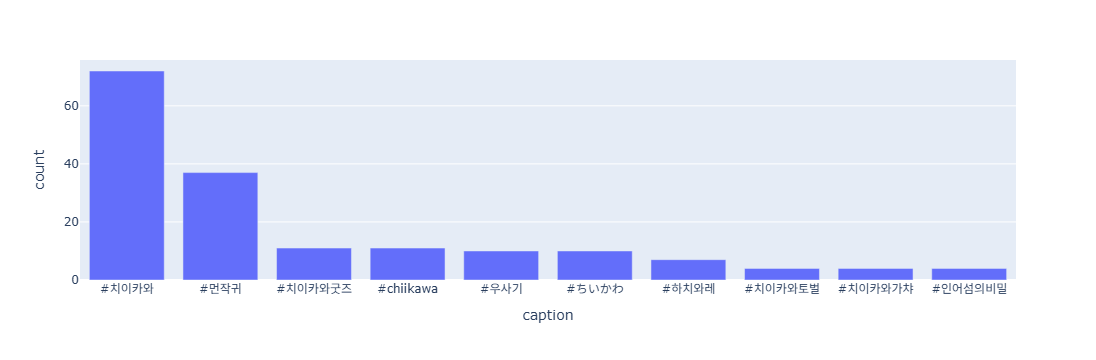

In [39]:
fig = px.bar(
    top10,
    x="caption",
    y="count"
)

fig.show()

In [24]:
df

,id,caption,media_type,permalink,timestamp,timestamp_kst
0,18098231099388616,치이카와 박스 입고 완료! 구매 문의는 DM주세용 #치이카와 #우사기 #치이카와굿즈,VIDEO,https://www.instagram.com/reel/DfGkV_go58T/,2026-10-30 03:02:21+00:00,2026-10-30 12:02:21+09:00
1,18093270125197476,우사기야 잡아먹히지않게 조심해😱😱😱 #페키니즈 #우사기 #먼작귀 #우나 #치이카와,VIDEO,https://www.instagram.com/reel/DfGkSbiOKyj/,2026-10-30 03:01:31+00:00,2026-10-30 12:01:31+09:00
2,17968503579190791,🫠치이카와 먼작귀 태엽자동차 피규어 치이카와에 진심인 사람… 일단 나 🚗💘 이 귀여...,IMAGE,https://www.instagram.com/p/DfGkIqgSoMU/,2026-10-30 02:59:16+00:00,2026-10-30 11:59:16+09:00
3,18015934313979690,금일 모두 업데이트 예정입니다💕 자사몰에 업데이트되며 가격은 추후 자사몰에서 확인부...,IMAGE,https://www.instagram.com/p/DfGjrSHq3Fs/,2026-10-30 02:58:59+00:00,2026-10-30 11:58:59+09:00
4,18012596162988014,🩵 치이카와 입고 안내 🩵 모두 매장 방문 구매만 가능 (｡˃ ᵕ ˂ )b (치이카...,CAROUSEL_ALBUM,https://www.instagram.com/p/DfGkF_rmqfH/,2026-10-30 02:58:45+00:00,2026-10-30 11:58:45+09:00
...,...,...,...,...,...,...
85,18032446877909302,"🫧 안녕하세요! 꽁떼드 코코링입니다. 🎀 조금 더 편하게 일상도 나누고, 좋아하는 ...",VIDEO,https://www.instagram.com/reel/DfGaysXyEnO/,2026-10-30 01:38:31+00:00,2026-10-30 10:38:31+09:00
86,18601739683064217,타오바오 공식 중국치이카와마켓에서 구매했습니다! 79.9위안 약 16000원이고 치...,VIDEO,https://www.instagram.com/reel/DfGabNWzo_4/,2026-10-30 01:37:58+00:00,2026-10-30 10:37:58+09:00
87,18125630717314180,웃겨서 사진만 빨리 찍으려고 했는데 얼굴에 불빵난 치이야.. 미안해.. #치이카와,CAROUSEL_ALBUM,https://www.instagram.com/p/DfGazs8k5vd/,2026-10-30 01:37:36+00:00,2026-10-30 10:37:36+09:00
88,17895391800435228,💭 1일 (일) 오후 6시 판매 예정 〰️ 🛶 ♡,IMAGE,https://www.instagram.com/p/DfGaxyyO82Y/,2026-10-30 01:37:23+00:00,2026-10-30 10:37:23+09:00
